# Modeling Dataset Notebook
This notebook contains the code required to construct the modeling dataset used for the linear and nonlinear shoreline-change models.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Set file locations

In [2]:
# Project root
ROOT_DIR = Path.cwd().parent

# Raw data folder
RAW_DIR = ROOT_DIR / "raw_data"

# Processed output folder
OUTPUT_DIR = ROOT_DIR / "processed"
OUTPUT_DIR.mkdir(exist_ok=True)

# Source data files
transect_file = RAW_DIR / "california_transect_lookup.csv"
characteristics_file = RAW_DIR / "CoastSat_Calif_SeasonalCycleData.csv"
wave_file = RAW_DIR / "CDIP_monthly_P_Dir_for_Calif_CoastSat.csv"
roni_file = RAW_DIR / "RONI.csv"
shoreline_folder = (RAW_DIR / "shoreline_data" / "shoreline_data_run6" / "USA_CA")

## Load source data

In [3]:
# Load California transect lookup table
transects = pd.read_csv(transect_file)
transects

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id
0,usa_CA_0001-0000,32.541036,-117.090530,32.540497,-117.094751,0.055,usa_CA_0001
1,usa_CA_0001-0001,32.540186,-117.090404,32.539561,-117.094611,0.055,usa_CA_0001
2,usa_CA_0001-0002,32.539377,-117.090236,32.538600,-117.094412,0.055,usa_CA_0001
3,usa_CA_0001-0003,32.538545,-117.090025,32.537677,-117.094179,0.055,usa_CA_0001
4,usa_CA_0001-0004,32.537684,-117.089791,32.536788,-117.093937,0.055,usa_CA_0001
...,...,...,...,...,...,...,...
8142,usa_CA_0309-0008,42.025368,-124.162039,42.022566,-124.165107,0.035,usa_CA_0309
8143,usa_CA_0309-0009,42.025944,-124.163029,42.023094,-124.166013,0.035,usa_CA_0309
8144,usa_CA_0309-0010,42.026500,-124.164078,42.023577,-124.166925,0.035,usa_CA_0309
8145,usa_CA_0309-0011,42.027014,-124.165104,42.024064,-124.167898,0.035,usa_CA_0309


In [4]:
# Load transect characteristics data
characteristics = pd.read_csv(characteristics_file)
characteristics

,CoastSat_Section,CoastSat_Transect,Lat_AvShoreline_WGS84,Lon_AvShoreline_WGS84,ShoreOrientation_deg,Lat_Backbeach_WGS84,Lon_Backbeach_WGS84,BeachWidth_m,STL_SeasonalExcurs_m,STL_Tmin_mo,STL_Tmax_mo,STL_pval_tTest,fft_SeasonalExcurs_m,Periodogram_pval_annual,k_Means_Cluster
0,1,0,32.551559,-117.127297,261.5,32.551711,-117.126116,112.1,24.1,5.0,10.0,0.000001,19.7,0.000000,6
1,1,1,32.550675,-117.127063,260.1,32.550872,-117.125739,126.2,19.7,4.0,9.0,0.000000,19.2,0.000000,6
2,1,2,32.549796,-117.126797,257.7,32.550061,-117.125374,136.8,22.4,5.0,10.0,0.000000,21.4,0.000000,6
3,1,3,32.548927,-117.126521,256.2,32.549243,-117.125006,146.4,20.4,3.0,9.0,0.000000,20.7,0.000000,6
4,1,4,32.548061,-117.126245,255.8,32.548409,-117.124631,156.4,23.9,3.0,10.0,0.000000,22.6,0.000000,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7772,309,8,42.010329,-124.223719,220.1,42.010853,-124.223144,75.2,14.5,5.0,12.0,0.000000,10.1,0.000337,8
7773,309,9,42.010825,-124.224707,218.8,42.011369,-124.224137,76.7,9.9,5.0,12.0,0.000055,7.6,0.035759,8
7774,309,10,42.011345,-124.225657,216.8,42.011899,-124.225116,76.1,11.7,5.0,1.0,0.000108,8.4,0.001943,9
7775,309,11,42.011853,-124.226638,216.1,42.012465,-124.226058,83.2,17.0,5.0,2.0,0.000021,10.8,0.001371,9


In [5]:
# Load wave data
waves = pd.read_csv(wave_file)
waves

,CoastSat_Section,CoastSat_Transect,AvP_Jan,AvP_Feb,AvP_Mar,AvP_Apr,AvP_May,AvP_Jun,AvP_Jul,AvP_Aug,...,AvDir_Mar,AvDir_Apr,AvDir_May,AvDir_Jun,AvDir_Jul,AvDir_Aug,AvDir_Sep,AvDir_Oct,AvDir_Nov,AvDir_Dec
0,1,0,6.62,6.02,5.86,5.17,4.16,3.32,2.51,2.32,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
1,1,1,6.62,6.02,5.86,5.17,4.16,3.32,2.51,2.32,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
2,1,2,6.62,6.02,5.86,5.17,4.16,3.32,2.51,2.32,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
3,1,3,7.72,7.04,6.67,5.69,4.45,3.50,2.55,2.34,...,262.1,262.3,259.4,254.9,252.2,253.9,255.2,259.4,262.6,263.1
4,1,4,7.35,6.72,6.47,5.64,4.42,3.57,2.59,2.37,...,262.5,262.5,258.5,254.2,252.2,254.1,254.5,259.6,263.2,263.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7772,309,8,19.16,16.68,13.15,9.78,5.52,5.05,3.67,3.40,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7
7773,309,9,19.16,16.68,13.15,9.78,5.52,5.05,3.67,3.40,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7
7774,309,10,19.16,16.68,13.15,9.78,5.52,5.05,3.67,3.40,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7
7775,309,11,19.16,16.68,13.15,9.78,5.52,5.05,3.67,3.40,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7


In [6]:
# Load RONI data
roni = pd.read_csv(roni_file)
roni

,winter,RONI
0,1999-2000,-1.5
1,2000-2001,-0.8
2,2001-2002,-0.2
3,2002-2003,0.9
4,2003-2004,0.2
5,2004-2005,0.5
6,2005-2006,-0.9
7,2006-2007,0.6
8,2007-2008,-1.7
9,2008-2009,-1.0


## Add section and transect numbers to transect lookup table for merge

In [7]:
parts = transects["transect_id"].str.replace("usa_CA_", "").str.split("-")

transects["CoastSat_Section"] = parts.str[0].astype(int)
transects["CoastSat_Transect"] = parts.str[1].astype(int)
transects

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id,CoastSat_Section,CoastSat_Transect
0,usa_CA_0001-0000,32.541036,-117.090530,32.540497,-117.094751,0.055,usa_CA_0001,1,0
1,usa_CA_0001-0001,32.540186,-117.090404,32.539561,-117.094611,0.055,usa_CA_0001,1,1
2,usa_CA_0001-0002,32.539377,-117.090236,32.538600,-117.094412,0.055,usa_CA_0001,1,2
3,usa_CA_0001-0003,32.538545,-117.090025,32.537677,-117.094179,0.055,usa_CA_0001,1,3
4,usa_CA_0001-0004,32.537684,-117.089791,32.536788,-117.093937,0.055,usa_CA_0001,1,4
...,...,...,...,...,...,...,...,...,...
8142,usa_CA_0309-0008,42.025368,-124.162039,42.022566,-124.165107,0.035,usa_CA_0309,309,8
8143,usa_CA_0309-0009,42.025944,-124.163029,42.023094,-124.166013,0.035,usa_CA_0309,309,9
8144,usa_CA_0309-0010,42.026500,-124.164078,42.023577,-124.166925,0.035,usa_CA_0309,309,10
8145,usa_CA_0309-0011,42.027014,-124.165104,42.024064,-124.167898,0.035,usa_CA_0309,309,11


## Build master feature table for Southern California transects

In [8]:
# Merge transects data with characteristics data
features = transects.merge(characteristics, on=["CoastSat_Section", "CoastSat_Transect"])
features

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id,CoastSat_Section,CoastSat_Transect,Lat_AvShoreline_WGS84,...,Lat_Backbeach_WGS84,Lon_Backbeach_WGS84,BeachWidth_m,STL_SeasonalExcurs_m,STL_Tmin_mo,STL_Tmax_mo,STL_pval_tTest,fft_SeasonalExcurs_m,Periodogram_pval_annual,k_Means_Cluster
0,usa_CA_0001-0000,32.541036,-117.090530,32.540497,-117.094751,0.055,usa_CA_0001,1,0,32.551559,...,32.551711,-117.126116,112.1,24.1,5.0,10.0,0.000001,19.7,0.000000,6
1,usa_CA_0001-0001,32.540186,-117.090404,32.539561,-117.094611,0.055,usa_CA_0001,1,1,32.550675,...,32.550872,-117.125739,126.2,19.7,4.0,9.0,0.000000,19.2,0.000000,6
2,usa_CA_0001-0002,32.539377,-117.090236,32.538600,-117.094412,0.055,usa_CA_0001,1,2,32.549796,...,32.550061,-117.125374,136.8,22.4,5.0,10.0,0.000000,21.4,0.000000,6
3,usa_CA_0001-0003,32.538545,-117.090025,32.537677,-117.094179,0.055,usa_CA_0001,1,3,32.548927,...,32.549243,-117.125006,146.4,20.4,3.0,9.0,0.000000,20.7,0.000000,6
4,usa_CA_0001-0004,32.537684,-117.089791,32.536788,-117.093937,0.055,usa_CA_0001,1,4,32.548061,...,32.548409,-117.124631,156.4,23.9,3.0,10.0,0.000000,22.6,0.000000,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7772,usa_CA_0309-0008,42.025368,-124.162039,42.022566,-124.165107,0.035,usa_CA_0309,309,8,42.010329,...,42.010853,-124.223144,75.2,14.5,5.0,12.0,0.000000,10.1,0.000337,8
7773,usa_CA_0309-0009,42.025944,-124.163029,42.023094,-124.166013,0.035,usa_CA_0309,309,9,42.010825,...,42.011369,-124.224137,76.7,9.9,5.0,12.0,0.000055,7.6,0.035759,8
7774,usa_CA_0309-0010,42.026500,-124.164078,42.023577,-124.166925,0.035,usa_CA_0309,309,10,42.011345,...,42.011899,-124.225116,76.1,11.7,5.0,1.0,0.000108,8.4,0.001943,9
7775,usa_CA_0309-0011,42.027014,-124.165104,42.024064,-124.167898,0.035,usa_CA_0309,309,11,42.011853,...,42.012465,-124.226058,83.2,17.0,5.0,2.0,0.000021,10.8,0.001371,9


In [9]:
# Merge transects + characteristics with wave data
features = features.merge(waves, on=["CoastSat_Section", "CoastSat_Transect"])
features

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id,CoastSat_Section,CoastSat_Transect,Lat_AvShoreline_WGS84,...,AvDir_Mar,AvDir_Apr,AvDir_May,AvDir_Jun,AvDir_Jul,AvDir_Aug,AvDir_Sep,AvDir_Oct,AvDir_Nov,AvDir_Dec
0,usa_CA_0001-0000,32.541036,-117.090530,32.540497,-117.094751,0.055,usa_CA_0001,1,0,32.551559,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
1,usa_CA_0001-0001,32.540186,-117.090404,32.539561,-117.094611,0.055,usa_CA_0001,1,1,32.550675,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
2,usa_CA_0001-0002,32.539377,-117.090236,32.538600,-117.094412,0.055,usa_CA_0001,1,2,32.549796,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
3,usa_CA_0001-0003,32.538545,-117.090025,32.537677,-117.094179,0.055,usa_CA_0001,1,3,32.548927,...,262.1,262.3,259.4,254.9,252.2,253.9,255.2,259.4,262.6,263.1
4,usa_CA_0001-0004,32.537684,-117.089791,32.536788,-117.093937,0.055,usa_CA_0001,1,4,32.548061,...,262.5,262.5,258.5,254.2,252.2,254.1,254.5,259.6,263.2,263.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7772,usa_CA_0309-0008,42.025368,-124.162039,42.022566,-124.165107,0.035,usa_CA_0309,309,8,42.010329,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7
7773,usa_CA_0309-0009,42.025944,-124.163029,42.023094,-124.166013,0.035,usa_CA_0309,309,9,42.010825,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7
7774,usa_CA_0309-0010,42.026500,-124.164078,42.023577,-124.166925,0.035,usa_CA_0309,309,10,42.011345,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7
7775,usa_CA_0309-0011,42.027014,-124.165104,42.024064,-124.167898,0.035,usa_CA_0309,309,11,42.011853,...,253.5,254.6,254.9,258.7,267.1,265.3,258.2,256.0,255.0,253.7


In [10]:
# Keep transects that are in Southern California (below 34.5 latitude)
features = features[features["Lat_AvShoreline_WGS84"] <= 34.5].copy()
features

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id,CoastSat_Section,CoastSat_Transect,Lat_AvShoreline_WGS84,...,AvDir_Mar,AvDir_Apr,AvDir_May,AvDir_Jun,AvDir_Jul,AvDir_Aug,AvDir_Sep,AvDir_Oct,AvDir_Nov,AvDir_Dec
0,usa_CA_0001-0000,32.541036,-117.090530,32.540497,-117.094751,0.055,usa_CA_0001,1,0,32.551559,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
1,usa_CA_0001-0001,32.540186,-117.090404,32.539561,-117.094611,0.055,usa_CA_0001,1,1,32.550675,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
2,usa_CA_0001-0002,32.539377,-117.090236,32.538600,-117.094412,0.055,usa_CA_0001,1,2,32.549796,...,259.4,259.0,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7
3,usa_CA_0001-0003,32.538545,-117.090025,32.537677,-117.094179,0.055,usa_CA_0001,1,3,32.548927,...,262.1,262.3,259.4,254.9,252.2,253.9,255.2,259.4,262.6,263.1
4,usa_CA_0001-0004,32.537684,-117.089791,32.536788,-117.093937,0.055,usa_CA_0001,1,4,32.548061,...,262.5,262.5,258.5,254.2,252.2,254.1,254.5,259.6,263.2,263.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3215,usa_CA_0126-0013,34.446710,-120.407344,34.443481,-120.405526,0.095,usa_CA_0126,126,13,34.447918,...,183.6,179.7,176.7,176.2,175.6,175.5,176.2,178.6,183.4,185.8
3216,usa_CA_0126-0014,34.446069,-120.408573,34.443134,-120.406144,0.090,usa_CA_0126,126,14,34.447562,...,181.9,177.9,175.0,174.6,174.0,173.9,174.6,177.0,181.6,184.2
3217,usa_CA_0126-0015,34.445406,-120.409645,34.442713,-120.406838,0.085,usa_CA_0126,126,15,34.447085,...,181.9,177.9,175.0,174.6,174.0,173.9,174.6,177.0,181.6,184.2
3218,usa_CA_0126-0016,34.444537,-120.410691,34.442292,-120.407353,0.080,usa_CA_0126,126,16,34.446496,...,179.7,175.9,172.6,172.2,171.6,171.5,172.2,174.8,179.3,181.9


In [11]:
!pip install geopandas contextily

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\pakin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


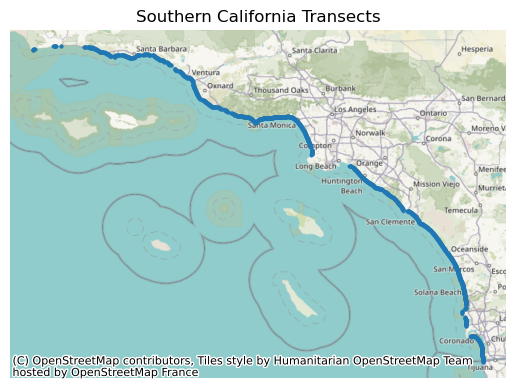

There are 3220 transects in Southern California.


In [12]:
# Plot Southern California transect locations
import geopandas as gpd
import contextily as ctx
import matplotlib.pyplot as plt

# Convert lat/lon columns to geographic points
map = gpd.GeoDataFrame(
    features,
    geometry=gpd.points_from_xy(
        features["Lon_AvShoreline_WGS84"],
        features["Lat_AvShoreline_WGS84"]
    ),
    crs="EPSG:4326"
)

# Convert to Web Mercator so it matches the basemap
map = map.to_crs(epsg=3857)

# Plot transects
map.plot(
    markersize=3,
    alpha=0.6,
)

ctx.add_basemap(plt.gca())

plt.title("Southern California Transects")
plt.axis("off")

plt.show()

socal_transects = features["transect_id"].nunique()
print(f"There are {socal_transects} transects in Southern California.")

In [13]:
# Saving master feature table
features.to_csv(OUTPUT_DIR / "master_transect_features.csv", index=False)

## Combine time-series data for transect shoreline positions

In [14]:
# Iterate through each site folder 
all_shorelines = []

for site_folder in shoreline_folder.iterdir():
    shoreline_file = site_folder / "time_series_tidally_corrected.csv"

    if shoreline_file.exists():
        df = pd.read_csv(shoreline_file)
        df = df.drop(columns=["Unnamed: 0"], errors="ignore")

        date_column = df.columns[0]

        df = df.melt(
            id_vars=date_column,
            var_name="transect_id",
            value_name="shoreline_position_m"
        )

        df = df.rename(columns={date_column: "date"})
        all_shorelines.append(df)

shoreline = pd.concat(all_shorelines, ignore_index=True)

shoreline["date"] = pd.to_datetime(shoreline["date"], errors="coerce")
shoreline["shoreline_position_m"] = pd.to_numeric(
    shoreline["shoreline_position_m"],
    errors="coerce"
)

print("Number of shoreline position observations in California:", len(shoreline))
shoreline.head(10)

Number of shoreline position observations in California: 6474041


,date,transect_id,shoreline_position_m
0,1984-03-23 17:50:13+00:00,usa_CA_0001-0000,261.790592
1,1984-05-06 17:49:52+00:00,usa_CA_0001-0000,260.733562
2,1984-06-07 17:50:43+00:00,usa_CA_0001-0000,265.368743
3,1984-06-23 17:50:58+00:00,usa_CA_0001-0000,270.314338
4,1984-08-26 17:52:34+00:00,usa_CA_0001-0000,274.015552
5,1984-12-16 17:52:39+00:00,usa_CA_0001-0000,NaN
6,1985-04-23 17:52:47+00:00,usa_CA_0001-0000,271.740527
7,1985-08-13 17:52:13+00:00,usa_CA_0001-0000,278.132489
8,1985-09-14 17:51:50+00:00,usa_CA_0001-0000,283.103936
9,1985-11-01 17:51:17+00:00,usa_CA_0001-0000,281.381639


In [15]:
# Keeping position observations for only Southern California transects
socal_transect_ids = features["transect_id"].unique()
socal_shoreline = shoreline[shoreline["transect_id"].isin(socal_transect_ids)].copy()

print("Number of shoreline position observations in Southern California:", len(socal_shoreline))
socal_shoreline.head(10)

Number of shoreline position observations in Southern California: 2768866


,date,transect_id,shoreline_position_m
0,1984-03-23 17:50:13+00:00,usa_CA_0001-0000,261.790592
1,1984-05-06 17:49:52+00:00,usa_CA_0001-0000,260.733562
2,1984-06-07 17:50:43+00:00,usa_CA_0001-0000,265.368743
3,1984-06-23 17:50:58+00:00,usa_CA_0001-0000,270.314338
4,1984-08-26 17:52:34+00:00,usa_CA_0001-0000,274.015552
5,1984-12-16 17:52:39+00:00,usa_CA_0001-0000,NaN
6,1985-04-23 17:52:47+00:00,usa_CA_0001-0000,271.740527
7,1985-08-13 17:52:13+00:00,usa_CA_0001-0000,278.132489
8,1985-09-14 17:51:50+00:00,usa_CA_0001-0000,283.103936
9,1985-11-01 17:51:17+00:00,usa_CA_0001-0000,281.381639


In [16]:
# Saving Southern California shoreline position time-series table
socal_shoreline.to_csv(OUTPUT_DIR / "shoreline_timeseries.csv", index=False)

## Isolate pre-winter and post-winter shoreline observations

In [17]:
# Keep October-November as the pre-winter period and March-April as the post winter period
socal_shoreline_full = socal_shoreline.copy()
socal_shoreline = socal_shoreline[socal_shoreline["date"].dt.month.isin([10, 11, 3, 4])].copy()

print("Number of shoreline position observations in Southern California before and after winter:", len(socal_shoreline))
socal_shoreline.head(10)

Number of shoreline position observations in Southern California before and after winter: 1039207


,date,transect_id,shoreline_position_m
0,1984-03-23 17:50:13+00:00,usa_CA_0001-0000,261.790592
6,1985-04-23 17:52:47+00:00,usa_CA_0001-0000,271.740527
9,1985-11-01 17:51:17+00:00,usa_CA_0001-0000,281.381639
10,1985-11-17 17:51:01+00:00,usa_CA_0001-0000,265.118583
19,1986-10-03 17:42:31+00:00,usa_CA_0001-0000,268.558606
20,1986-11-04 17:41:25+00:00,usa_CA_0001-0000,274.504488
25,1987-03-28 17:44:54+00:00,usa_CA_0001-0000,249.412162
26,1987-04-13 17:45:26+00:00,usa_CA_0001-0000,248.231820
33,1988-03-30 17:52:35+00:00,usa_CA_0001-0000,236.319972
39,1989-03-17 17:51:38+00:00,usa_CA_0001-0000,262.000740


In [18]:
# Assign winter label by year based on date
def get_winter(date):

    # October-November belong to the winter beginning that year
    if date.month in [10, 11]:
        return f"{date.year}-{date.year + 1}"

    # March-April belong to the winter of the previous year
    else:
        return f"{date.year - 1}-{date.year}"

socal_shoreline["winter"] = socal_shoreline["date"].apply(get_winter)

# Label observations based on whether they occurred before or after the winter season
socal_shoreline["period"] = np.where(socal_shoreline["date"].dt.month.isin([10, 11]), "pre_winter", "post_winter")
socal_shoreline.head(10)

,date,transect_id,shoreline_position_m,winter,period
0,1984-03-23 17:50:13+00:00,usa_CA_0001-0000,261.790592,1983-1984,post_winter
6,1985-04-23 17:52:47+00:00,usa_CA_0001-0000,271.740527,1984-1985,post_winter
9,1985-11-01 17:51:17+00:00,usa_CA_0001-0000,281.381639,1985-1986,pre_winter
10,1985-11-17 17:51:01+00:00,usa_CA_0001-0000,265.118583,1985-1986,pre_winter
19,1986-10-03 17:42:31+00:00,usa_CA_0001-0000,268.558606,1986-1987,pre_winter
20,1986-11-04 17:41:25+00:00,usa_CA_0001-0000,274.504488,1986-1987,pre_winter
25,1987-03-28 17:44:54+00:00,usa_CA_0001-0000,249.412162,1986-1987,post_winter
26,1987-04-13 17:45:26+00:00,usa_CA_0001-0000,248.231820,1986-1987,post_winter
33,1988-03-30 17:52:35+00:00,usa_CA_0001-0000,236.319972,1987-1988,post_winter
39,1989-03-17 17:51:38+00:00,usa_CA_0001-0000,262.000740,1988-1989,post_winter


In [19]:
# Restrict timeframe to winters between 2000 and 2022 for CoastSat data
socal_shoreline = socal_shoreline[(socal_shoreline["winter"] >= "2000-2001") & (socal_shoreline["winter"] <= "2021-2022")].copy()
socal_shoreline

,date,transect_id,shoreline_position_m,winter,period
177,2000-10-01 18:12:59+00:00,usa_CA_0001-0000,281.326545,2000-2001,pre_winter
178,2000-10-09 18:01:02+00:00,usa_CA_0001-0000,278.423775,2000-2001,pre_winter
179,2000-11-02 18:12:54+00:00,usa_CA_0001-0000,277.609103,2000-2001,pre_winter
180,2000-11-18 18:12:52+00:00,usa_CA_0001-0000,286.509282,2000-2001,pre_winter
181,2000-11-26 18:01:45+00:00,usa_CA_0001-0000,271.843403,2000-2001,pre_winter
...,...,...,...,...,...
2909418,2021-11-02 18:34:56+00:00,usa_CA_0126-0017,176.423122,2021-2022,pre_winter
2909419,2021-11-10 17:26:50+00:00,usa_CA_0126-0017,183.090464,2021-2022,pre_winter
2909420,2021-11-18 18:34:50+00:00,usa_CA_0126-0017,171.079652,2021-2022,pre_winter
2909421,2021-11-25 18:41:02+00:00,usa_CA_0126-0017,184.633881,2021-2022,pre_winter


## Calculate pre-winter and post-winter shoreline change

In [20]:
# Remove missing shoreline positions and sort by date
shoreline_clean = (
    socal_shoreline
    .dropna(subset=["shoreline_position_m"])
    .copy()
)

# Calculate average shoreline position for each transect, winter, and pre/post period
period_positions = (
    shoreline_clean
    .groupby(["transect_id", "winter", "period"])
    .agg(
        mean_position = ("shoreline_position_m", "mean"),
        observation_count = ("shoreline_position_m", "count")
    )
    .reset_index()
)
period_positions

,transect_id,winter,period,mean_position,observation_count
0,usa_CA_0001-0000,2000-2001,post_winter,241.230833,2
1,usa_CA_0001-0000,2000-2001,pre_winter,279.142422,5
2,usa_CA_0001-0000,2001-2002,post_winter,252.452749,2
3,usa_CA_0001-0000,2001-2002,pre_winter,275.536097,5
4,usa_CA_0001-0000,2002-2003,post_winter,240.504977,3
...,...,...,...,...,...
136836,usa_CA_0126-0017,2019-2020,post_winter,178.369863,4
136837,usa_CA_0126-0017,2019-2020,pre_winter,176.387157,7
136838,usa_CA_0126-0017,2020-2021,post_winter,180.878163,6
136839,usa_CA_0126-0017,2020-2021,pre_winter,177.140520,5


In [21]:
# Reshape mean positions so each transect-winter has one pre-winter and one post-winter position
winter_change = (
    period_positions
    .pivot(
        index=["transect_id", "winter"],
        columns="period",
        values="mean_position"
    )
    .reset_index()
)

# Reshape observation counts for coverage filtering
period_counts = (
    period_positions
    .pivot(
        index=["transect_id", "winter"],
        columns="period",
        values="observation_count"
    )
    .reset_index()
    .rename(
        columns={
            "pre_winter": "pre_observation_count",
            "post_winter": "post_observation_count"
        }
    )
)

winter_change = winter_change.merge(
    period_counts,
    on=["transect_id", "winter"],
    how="left"
)

# Keep only transect-winters with at least two observations in both pre- and post-winter periods
winter_change = winter_change[(winter_change["pre_observation_count"] >= 2) & (winter_change["post_observation_count"] >= 2)].copy()

# Calculate seasonal shoreline change:  post-winter position - pre-winter position
winter_change["shoreline_change_m"] = (winter_change["post_winter"] - winter_change["pre_winter"])
winter_change

period,transect_id,winter,post_winter,pre_winter,post_observation_count,pre_observation_count,shoreline_change_m
0,usa_CA_0001-0000,2000-2001,241.230833,279.142422,2.0,5.0,-37.911589
1,usa_CA_0001-0000,2001-2002,252.452749,275.536097,2.0,5.0,-23.083348
2,usa_CA_0001-0000,2002-2003,240.504977,262.722290,3.0,3.0,-22.217313
4,usa_CA_0001-0000,2004-2005,253.956259,256.911828,5.0,3.0,-2.955568
5,usa_CA_0001-0000,2005-2006,242.680609,264.600313,4.0,4.0,-21.919705
...,...,...,...,...,...,...,...
70834,usa_CA_0126-0017,2016-2017,185.019130,201.755371,9.0,7.0,-16.736241
70835,usa_CA_0126-0017,2017-2018,178.097185,181.043649,5.0,8.0,-2.946463
70836,usa_CA_0126-0017,2018-2019,177.544224,176.235002,6.0,10.0,1.309222
70837,usa_CA_0126-0017,2019-2020,178.369863,176.387157,4.0,7.0,1.982706


In [22]:
print("Rows:", len(winter_change))
print("Transects:", winter_change["transect_id"].nunique())
print("Winters:", winter_change["winter"].nunique())
winter_change["shoreline_change_m"].describe()

Rows: 60864
Transects: 3220
Winters: 21


count    60864.000000
mean        -7.167295
std         11.525634
min       -118.691334
25%        -12.882120
50%         -6.346523
75%         -0.771086
max        133.073099
Name: shoreline_change_m, dtype: float64

In [23]:
# Saving winter shoreline change table
winter_change.to_csv(OUTPUT_DIR / "winter_shoreline_change.csv", index=False)

## Create features for models

Features pertaining to directionality (shore orientation and wave direction) are converted into sine and cosine components to account for the circular nature of directional data in linear models.

In [24]:
# Convert shore orientation from characteristics 
orientation_rad = np.deg2rad(features["ShoreOrientation_deg"])

# Add shore orientation features in sin/cos
features["shore_orientation_sin"] = np.sin(orientation_rad)
features["shore_orientation_cos"] = np.cos(orientation_rad)
features.head(1)

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id,CoastSat_Section,CoastSat_Transect,Lat_AvShoreline_WGS84,...,AvDir_May,AvDir_Jun,AvDir_Jul,AvDir_Aug,AvDir_Sep,AvDir_Oct,AvDir_Nov,AvDir_Dec,shore_orientation_sin,shore_orientation_cos
0,usa_CA_0001-0000,32.541036,-117.09053,32.540497,-117.094751,0.055,usa_CA_0001,1,0,32.551559,...,255.5,251.8,250.7,252.2,252.8,255.9,259.4,260.7,-0.989016,-0.147809


In [25]:
# Find average wave power across the October-April analysis window
features["winter_wave_power"] = (features[["AvP_Oct", "AvP_Nov", "AvP_Dec", "AvP_Jan", "AvP_Feb", "AvP_Mar", "AvP_Apr"]].mean(axis=1))

# Convert monthly wave directions to radians
oct_dir = np.deg2rad(features["AvDir_Oct"])
nov_dir = np.deg2rad(features["AvDir_Nov"])
dec_dir = np.deg2rad(features["AvDir_Dec"])
jan_dir = np.deg2rad(features["AvDir_Jan"])
feb_dir = np.deg2rad(features["AvDir_Feb"])
mar_dir = np.deg2rad(features["AvDir_Mar"])
apr_dir = np.deg2rad(features["AvDir_Apr"])

# Add average winter wave direction features in sin/cos
features["wave_dir_sin"] = (np.sin(oct_dir) + np.sin(nov_dir) + np.sin(dec_dir) + np.sin(jan_dir) + np.sin(feb_dir) + np.sin(mar_dir) + np.sin(apr_dir)) / 7
features["wave_dir_cos"] = (np.cos(oct_dir) + np.cos(nov_dir) + np.cos(dec_dir) + np.cos(jan_dir) + np.cos(feb_dir) + np.cos(mar_dir) + np.cos(apr_dir)) / 7

features.head(5)

,transect_id,origin_lat,origin_lon,seaward_lat,seaward_lon,beach_slope,site_id,CoastSat_Section,CoastSat_Transect,Lat_AvShoreline_WGS84,...,AvDir_Aug,AvDir_Sep,AvDir_Oct,AvDir_Nov,AvDir_Dec,shore_orientation_sin,shore_orientation_cos,winter_wave_power,wave_dir_sin,wave_dir_cos
0,usa_CA_0001-0000,32.541036,-117.090530,32.540497,-117.094751,0.055,usa_CA_0001,1,0,32.551559,...,252.2,252.8,255.9,259.4,260.7,-0.989016,-0.147809,5.104286,-0.982233,-0.185844
1,usa_CA_0001-0001,32.540186,-117.090404,32.539561,-117.094611,0.055,usa_CA_0001,1,1,32.550675,...,252.2,252.8,255.9,259.4,260.7,-0.985109,-0.171929,5.104286,-0.982233,-0.185844
2,usa_CA_0001-0002,32.539377,-117.090236,32.538600,-117.094412,0.055,usa_CA_0001,1,2,32.549796,...,252.2,252.8,255.9,259.4,260.7,-0.977046,-0.213030,5.104286,-0.982233,-0.185844
3,usa_CA_0001-0003,32.538545,-117.090025,32.537677,-117.094179,0.055,usa_CA_0001,1,3,32.548927,...,253.9,255.2,259.4,262.6,263.1,-0.971134,-0.238533,5.928571,-0.990016,-0.139639
4,usa_CA_0001-0004,32.537684,-117.089791,32.536788,-117.093937,0.055,usa_CA_0001,1,4,32.548061,...,254.1,254.5,259.6,263.2,263.6,-0.969445,-0.245307,5.715714,-0.991061,-0.131730


In [26]:
# Feature selection
selected_features = features[["transect_id", "BeachWidth_m", "beach_slope", "shore_orientation_sin", "shore_orientation_cos", "winter_wave_power", "wave_dir_sin", "wave_dir_cos"]].copy()
selected_features

,transect_id,BeachWidth_m,beach_slope,shore_orientation_sin,shore_orientation_cos,winter_wave_power,wave_dir_sin,wave_dir_cos
0,usa_CA_0001-0000,112.1,0.055,-0.989016,-0.147809,5.104286,-0.982233,-0.185844
1,usa_CA_0001-0001,126.2,0.055,-0.985109,-0.171929,5.104286,-0.982233,-0.185844
2,usa_CA_0001-0002,136.8,0.055,-0.977046,-0.213030,5.104286,-0.982233,-0.185844
3,usa_CA_0001-0003,146.4,0.055,-0.971134,-0.238533,5.928571,-0.990016,-0.139639
4,usa_CA_0001-0004,156.4,0.055,-0.969445,-0.245307,5.715714,-0.991061,-0.131730
...,...,...,...,...,...,...,...,...
3215,usa_CA_0126-0013,63.6,0.095,0.447759,-0.894154,2.562857,-0.056017,-0.997274
3216,usa_CA_0126-0014,60.9,0.090,0.587785,-0.809017,2.577143,-0.026904,-0.998455
3217,usa_CA_0126-0015,63.9,0.085,0.674302,-0.738455,2.577143,-0.026904,-0.998455
3218,usa_CA_0126-0016,63.9,0.080,0.794415,-0.607376,2.527143,0.011944,-0.998810


In [27]:
# Saving model features table
selected_features.to_csv(OUTPUT_DIR / "model_features.csv", index=False)

## Create modeling dataset

In [28]:
# Merge winter dataset with RONI values
model_data = winter_change.merge(
    selected_features,
    on="transect_id",
    how="inner"
)

model_data = model_data.merge(
    roni,
    on="winter",
    how="left"
)

model_data

,transect_id,winter,post_winter,pre_winter,post_observation_count,pre_observation_count,shoreline_change_m,BeachWidth_m,beach_slope,shore_orientation_sin,shore_orientation_cos,winter_wave_power,wave_dir_sin,wave_dir_cos,RONI
0,usa_CA_0001-0000,2000-2001,241.230833,279.142422,2.0,5.0,-37.911589,112.1,0.055,-0.989016,-0.147809,5.104286,-0.982233,-0.185844,-0.8
1,usa_CA_0001-0000,2001-2002,252.452749,275.536097,2.0,5.0,-23.083348,112.1,0.055,-0.989016,-0.147809,5.104286,-0.982233,-0.185844,-0.2
2,usa_CA_0001-0000,2002-2003,240.504977,262.722290,3.0,3.0,-22.217313,112.1,0.055,-0.989016,-0.147809,5.104286,-0.982233,-0.185844,0.9
3,usa_CA_0001-0000,2004-2005,253.956259,256.911828,5.0,3.0,-2.955568,112.1,0.055,-0.989016,-0.147809,5.104286,-0.982233,-0.185844,0.5
4,usa_CA_0001-0000,2005-2006,242.680609,264.600313,4.0,4.0,-21.919705,112.1,0.055,-0.989016,-0.147809,5.104286,-0.982233,-0.185844,-0.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60859,usa_CA_0126-0017,2016-2017,185.019130,201.755371,9.0,7.0,-16.736241,71.3,0.055,0.850811,-0.525472,2.527143,0.011944,-0.998810,-0.6
60860,usa_CA_0126-0017,2017-2018,178.097185,181.043649,5.0,8.0,-2.946463,71.3,0.055,0.850811,-0.525472,2.527143,0.011944,-0.998810,-1.1
60861,usa_CA_0126-0017,2018-2019,177.544224,176.235002,6.0,10.0,1.309222,71.3,0.055,0.850811,-0.525472,2.527143,0.011944,-0.998810,0.7
60862,usa_CA_0126-0017,2019-2020,178.369863,176.387157,4.0,7.0,1.982706,71.3,0.055,0.850811,-0.525472,2.527143,0.011944,-0.998810,0.1


In [29]:
# Check table and values
print("Rows:", len(model_data))
print("Transects:", model_data["transect_id"].nunique())
print("Winters:", model_data["winter"].nunique())

print(
    "Duplicate transect/winter rows:",
    model_data.duplicated(
        ["transect_id", "winter"]
    ).sum()
)

print("\nMissing values:")
print(model_data.isna().sum())

Rows: 60864
Transects: 3220
Winters: 21
Duplicate transect/winter rows: 0

Missing values:
transect_id                 0
winter                      0
post_winter                 0
pre_winter                  0
post_observation_count      0
pre_observation_count       0
shoreline_change_m          0
BeachWidth_m                0
beach_slope               740
shore_orientation_sin       0
shore_orientation_cos       0
winter_wave_power           0
wave_dir_sin                0
wave_dir_cos                0
RONI                        0
dtype: int64


In [30]:
# Saving final modeling dataset
model_data.to_csv(OUTPUT_DIR / "final_modeling_dataset.csv", index=False)

In the modeling dataset, each row represents one Southern California transect during one winter season within the 2000 and 2022 source data period. The dataset contains the winter shoreline change target (shoreline_change_m), beach morphology features (BeachWidth_m, beach_slope, shore_orientation_sin, shore_orientation_cos), characteristic winter wave features (winter_wave_power, wave_dir_sin, wave_dir_cos), and the corresponding winter RONI value. The shoreline change target (shoreline_change_m) is calculated as the average March–April shoreline position minus the average October–November shoreline position preceding that winter. Negative values represent shoreline retreat and positive values represent accretion. Different subsets of these predictors will be used for the three linear regression models.

## EDA

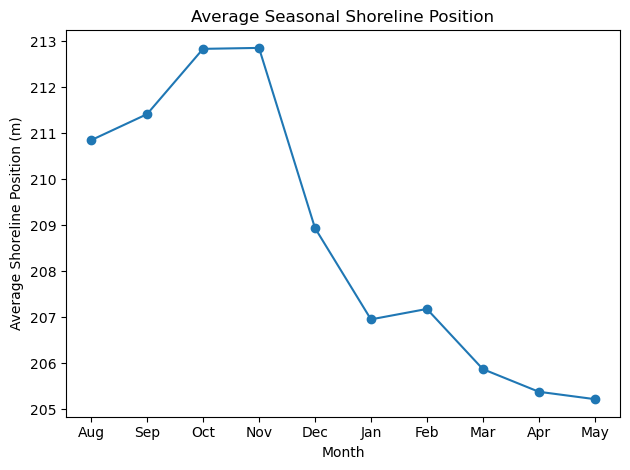

In [31]:
# Average shoreline position by month
monthly_data = socal_shoreline_full.dropna(subset=["shoreline_position_m"]).copy()
monthly_data["month"] = monthly_data["date"].dt.month

monthly_shoreline = (
    monthly_data
    .groupby("month")["shoreline_position_m"]
    .mean()
    .reset_index()
)

months = [8, 9, 10, 11, 12, 1, 2, 3, 4, 5]
month_names = ["Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May"]

monthly_plot = (
    monthly_shoreline
    .set_index("month")
    .loc[months]
    .reset_index()
)

plt.plot(
    month_names,
    monthly_plot["shoreline_position_m"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average Shoreline Position (m)")
plt.title("Average Seasonal Shoreline Position")

plt.tight_layout()
plt.show()

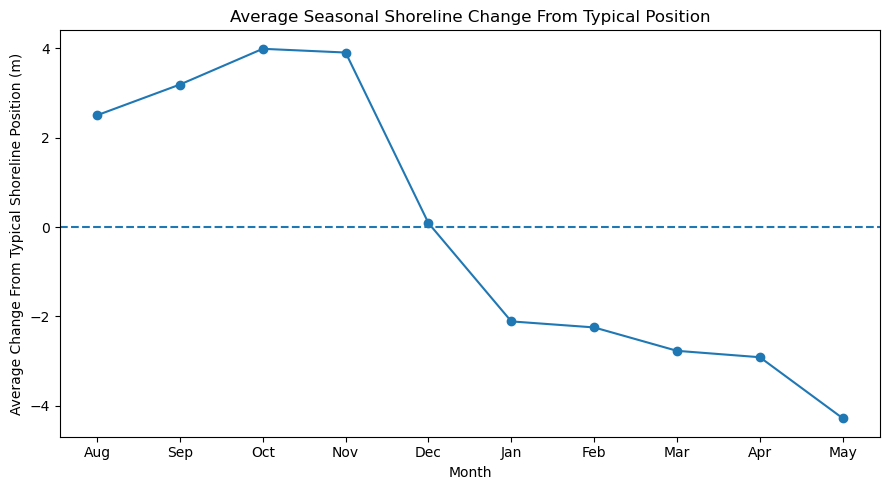

,month,mean_shoreline_anomaly,observations
0,8,2.502664,159400
1,9,3.190319,160785
2,10,3.990487,172306
3,11,3.906924,182780
4,12,0.087344,144906
5,1,-2.113300,167373
6,2,-2.248136,161269
7,3,-2.772161,153285
8,4,-2.915513,176148
9,5,-4.281831,129013


In [32]:
# Average seasonal shoreline change from each transect's typical position
monthly_data = socal_shoreline_full.dropna(
    subset=["shoreline_position_m"]
).copy()

monthly_data = monthly_data[
    monthly_data["date"].dt.year.between(2000, 2021)
].copy()

# Center each observation relative to that transect's typical shoreline position.
monthly_data["shoreline_anomaly"] = (
    monthly_data["shoreline_position_m"]
    - monthly_data.groupby("transect_id")["shoreline_position_m"].transform("median")
)

monthly_data["month"] = monthly_data["date"].dt.month

monthly_shoreline = (
    monthly_data
    .groupby("month")
    .agg(
        mean_shoreline_anomaly=("shoreline_anomaly", "mean"),
        observations=("shoreline_anomaly", "count")
    )
    .reset_index()
)

months = [8, 9, 10, 11, 12, 1, 2, 3, 4, 5]
month_names = ["Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May"]

monthly_plot = (
    monthly_shoreline
    .set_index("month")
    .loc[months]
    .reset_index()
)

plt.figure(figsize=(9, 5))

plt.plot(
    month_names,
    monthly_plot["mean_shoreline_anomaly"],
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.xlabel("Month")
plt.ylabel("Average Change From Typical Shoreline Position (m)")
plt.title("Average Seasonal Shoreline Change From Typical Position")

plt.tight_layout()
plt.show()

display(monthly_plot)

Average shoreline position follows a clear seasonal pattern, with shorelines generally farther seaward during October and November before progressively eroding through the winter and early spring. 

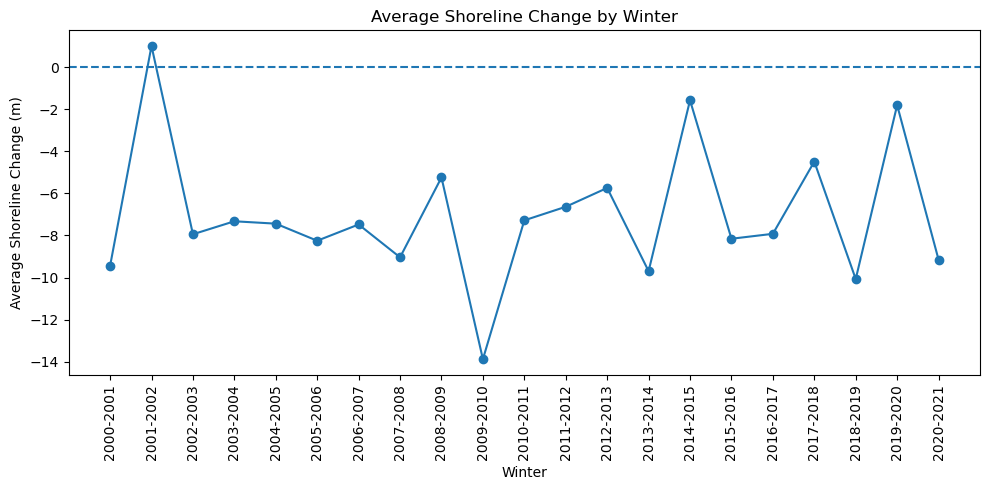

,winter,mean_shoreline_change,median_shoreline_change,observations,RONI
0,2000-2001,-9.446922,-8.408103,2330,-0.8
1,2001-2002,1.000470,0.407605,1760,-0.2
2,2002-2003,-7.942587,-7.192855,2891,0.9
3,2003-2004,-7.325587,-6.467486,2887,0.2
4,2004-2005,-7.438657,-6.875836,3092,0.5
5,2005-2006,-8.249763,-7.213451,3141,-0.9
6,2006-2007,-7.477840,-6.072472,2451,0.6
7,2007-2008,-9.038477,-8.232282,2753,-1.7
8,2008-2009,-5.244753,-5.226057,3217,-1.0
9,2009-2010,-13.876733,-12.329513,3209,1.4


In [33]:
# Average shoreline change by winter season
winter_summary = (
    model_data
    .groupby("winter")
    .agg(
        mean_shoreline_change=("shoreline_change_m", "mean"),
        median_shoreline_change=("shoreline_change_m", "median"),
        observations=("shoreline_change_m", "count"),
        RONI=("RONI", "first")
    )
    .reset_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    winter_summary["winter"],
    winter_summary["mean_shoreline_change"],
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.xlabel("Winter")
plt.ylabel("Average Shoreline Change (m)")
plt.title("Average Shoreline Change by Winter")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

display(winter_summary)

Average shoreline change varies considerably between winter seasons, with some winters experiencing substantially greater retreat than others.

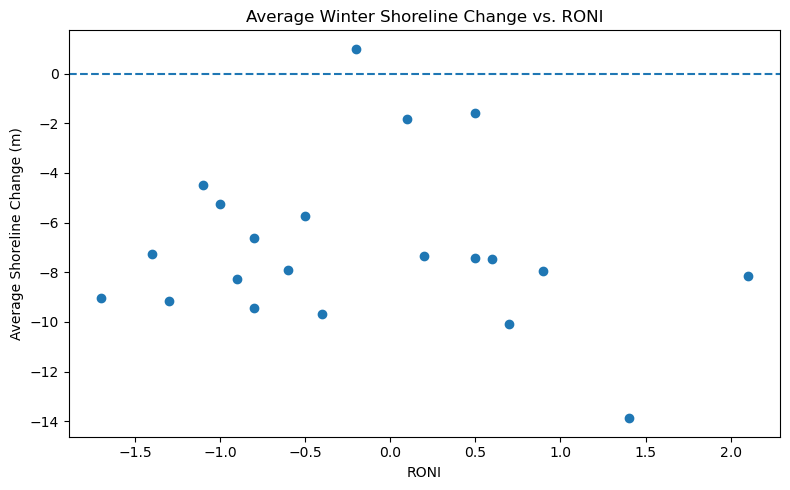

Correlation between winter RONI and average shoreline change: -0.1256


In [34]:
# Average winter shoreline change vs. RONI
roni_plot_data = winter_summary.dropna(
    subset=["RONI", "mean_shoreline_change"]
).copy()

plt.figure(figsize=(8, 5))

plt.scatter(
    roni_plot_data["RONI"],
    roni_plot_data["mean_shoreline_change"]
)

plt.axhline(0, linestyle="--")

plt.xlabel("RONI")
plt.ylabel("Average Shoreline Change (m)")
plt.title("Average Winter Shoreline Change vs. RONI")

plt.tight_layout()
plt.show()

roni_correlation = roni_plot_data[
    ["RONI", "mean_shoreline_change"]
].corr().iloc[0, 1]

print(f"Correlation between winter RONI and average shoreline change: {roni_correlation:.4f}")

RONI is only weakly negatively related to average winter shoreline change, indicating that stronger El Niño conditions are associated with somewhat greater retreat but does not solely explain most of the observed variation.

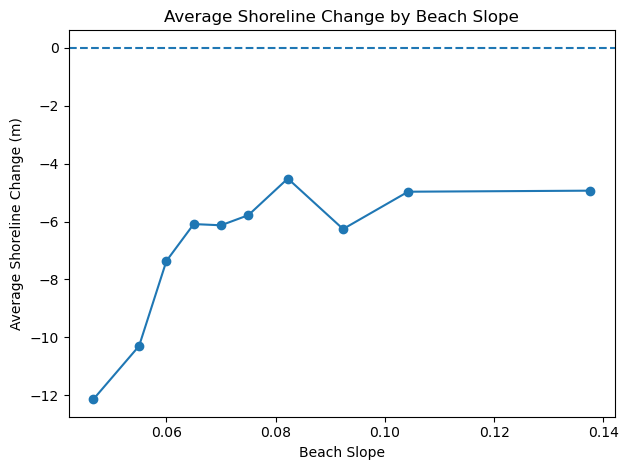

In [35]:
# Beach slope vs. shoreline change
model_data["slope_bin"] = pd.qcut(
    model_data["beach_slope"],
    10,
    duplicates="drop"
)

slope_summary = model_data.groupby(
    "slope_bin",
    observed=True
).agg({
    "beach_slope": "mean",
    "shoreline_change_m": "mean"
}).reset_index()

plt.plot(
    slope_summary["beach_slope"],
    slope_summary["shoreline_change_m"],
    marker="o"
)

plt.axhline(0, linestyle="--")
plt.xlabel("Beach Slope")
plt.ylabel("Average Shoreline Change (m)")
plt.title("Average Shoreline Change by Beach Slope")
plt.tight_layout()
plt.show()

Beach slope shows a general pattern in which flatter beaches experience greater average shoreline retreat.

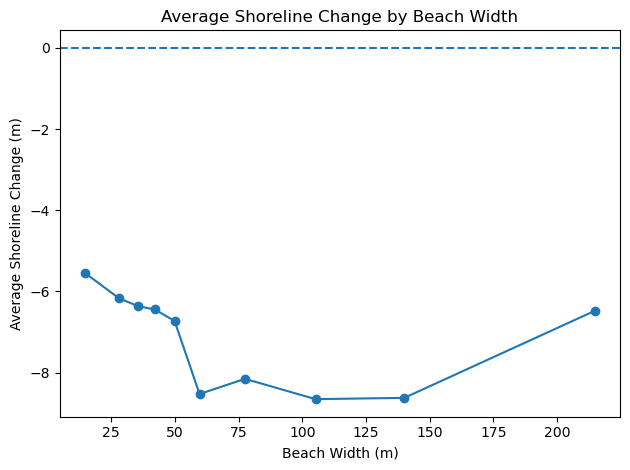

In [36]:
# Beach width vs. shoreline change
model_data["width_bin"] = pd.qcut(
    model_data["BeachWidth_m"],
    10,
    duplicates="drop"
)

width_summary = model_data.groupby(
    "width_bin",
    observed=True
).agg({
    "BeachWidth_m": "mean",
    "shoreline_change_m": "mean"
}).reset_index()

plt.plot(
    width_summary["BeachWidth_m"],
    width_summary["shoreline_change_m"],
    marker="o"
)

plt.axhline(0, linestyle="--")
plt.xlabel("Beach Width (m)")
plt.ylabel("Average Shoreline Change (m)")
plt.title("Average Shoreline Change by Beach Width")
plt.tight_layout()
plt.show()

Beach width shows a nonlinear relationship with shoreline change, suggesting that width alone does not consistently determine erosion vulnerability.

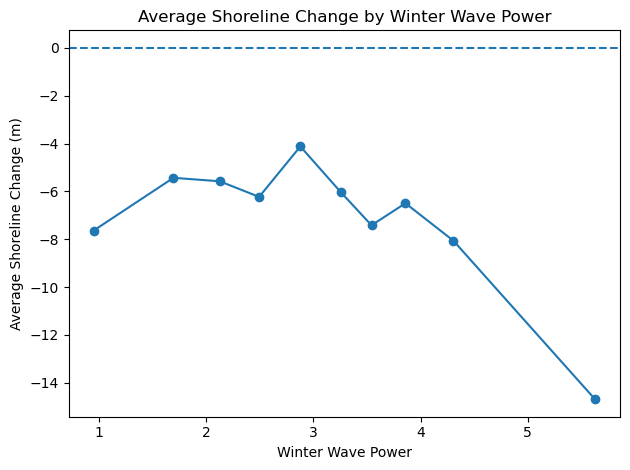

In [37]:
# Wave power vs. shoreline change
model_data["wave_power_bin"] = pd.qcut(
    model_data["winter_wave_power"],
    10,
    duplicates="drop"
)

wave_summary = model_data.groupby(
    "wave_power_bin",
    observed=True
).agg({
    "winter_wave_power": "mean",
    "shoreline_change_m": "mean"
}).reset_index()

plt.plot(
    wave_summary["winter_wave_power"],
    wave_summary["shoreline_change_m"],
    marker="o"
)

plt.axhline(0, linestyle="--")
plt.xlabel("Winter Wave Power")
plt.ylabel("Average Shoreline Change (m)")
plt.title("Average Shoreline Change by Winter Wave Power")
plt.tight_layout()
plt.show()

Stronger wave power is generally associated with greater average shoreline retreat.